In [1]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import json
import joblib
from datetime import datetime
warnings.filterwarnings("ignore")

# Machine Learning Models and Evaluation Metrics
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             brier_score_loss, precision_score, recall_score, f1_score,
                             accuracy_score, precision_recall_curve, average_precision_score)
from xgboost import XGBClassifier

# Imbalanced Learning & Data Pipelines
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder

# Data Structures and Typing
from dataclasses import dataclass
from collections import defaultdict

# Advanced Gradient Boosting Models
import lightgbm as lgb

# Global Random State for Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Runtime Configuration
FAST_MODE = True
print("All Python libraries have been imported successfully!")
print("Ready for feature engineering and credit risk modeling.")
print(f"Fast run mode: {'Enabled' if FAST_MODE else 'Disabled'}")
print("Random Seed:", RANDOM_STATE)

d:\credit-default-classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All Python libraries have been imported successfully!
Ready for feature engineering and credit risk modeling.
Fast run mode: Enabled
Random Seed: 42


In [2]:
# Read data
data_path = "../data/processed/data_extracted.parquet"
df = pd.read_parquet(data_path)
df.head()

# Normalize column names to lowercase
df.columns = df.columns.str.lower()
print("Column names have been normalized to lowercase.")
print(f"Loaded dataset successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")

Column names have been normalized to lowercase.
Loaded dataset successfully: 14,000 rows x 88 columns


In [3]:
# ==============================================================================
# Cell 3: Domain-Specific Feature Engineering & Missing Risk Indicators
# ==============================================================================

def feature_engineering(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """
    Advanced Feature Engineering Pipeline for Credit Risk Scoring:
    - Step 1: Detect and remove data leakage proxies, PII identifiers, and constant features.
    - Step 2: Normalize financial units: month_incom is converted to Million VND (income_m)
              matching outstanding balances and debt exposure units.
    - Step 3: Handle credit card code -1 (non-cardholders) cleanly with has_active_cc flag.
    - Step 4: Compute financial affordability and debt burden ratios (LTI, DTI, Total Exposure).
    - Step 5: Calculate non-bank and subprime loan exposure ratios.
    - Step 6: Engineer credit card utilization and credit stress indicators.
    - Step 7: Create inquiry velocity burst and debt trajectory features.
    - Step 8: Construct demographic and historical credit delinquency flags.
    """
    print("=" * 15, "FEATURE LEAKAGE DETECTION & ADVANCED FEATURE ENGINEERING", "=" * 15)
    
    # --------------------------------------------------------------------------
    # 1. Leakage Detection and Identifier Cleansing
    # --------------------------------------------------------------------------
    print("1. Removing forbidden features and PII identifiers...")
    forbidden_patterns = ['fpd', 'collection', 'recovery', 'writeoff', 'chargeoff',
                          'overdue_days', 'cic_data', 'address', 'dia_chi', 'disbursement_date']
    id_exact_patterns = ['customer_id', 'cif', 'contract_id', 'app_id', 'id_number', 'phone', 'email']

    cols_to_drop = set()
    for col in df.columns:
        if col == target_col:
            continue
        c_lower = col.lower().strip()
        if any(pat in c_lower for pat in forbidden_patterns):
            cols_to_drop.add(col)
        elif 'dpd' in c_lower and col != target_col:
            cols_to_drop.add(col)
        elif any(id_pat in c_lower for id_pat in id_exact_patterns) or c_lower in ['id', 'cif_no']:
            cols_to_drop.add(col)
        elif df[col].nunique(dropna=False) <= 1:
            cols_to_drop.add(col)

    df_feat = df.drop(columns=list(cols_to_drop)).copy()

    # --------------------------------------------------------------------------
    # 2. Financial Unit Normalization (Convert raw VND income to Million VND)
    # month_incom is in VND (~10M). Balances, CC limits & CIC loans are in Million VND (~10-50M).
    # --------------------------------------------------------------------------
    income_raw = df_feat['month_incom'].fillna(df_feat['month_incom'].median())
    income_m = np.clip(income_raw, 1_000_000, 50_000_000) / 1_000_000.0
    df_feat['income_m'] = income_m
    df_feat['log_income'] = np.log1p(income_m)

    # --------------------------------------------------------------------------
    # 3. Missingness Indicators (Signals for Underbanked / Thin-File Borrowers)
    # --------------------------------------------------------------------------
    print("2. Generating missingness indicator flags...")
    df_feat['flag_missing_income'] = df_feat['month_incom'].isna().astype(int)
    df_feat['flag_missing_cic_util'] = df_feat['cic_cc_util'].isna().astype(int)
    df_feat['flag_thin_file'] = (df_feat['has_cic'] == 0).astype(int)

    # --------------------------------------------------------------------------
    # 4. Financial Affordability Ratios (Strict unit-matched division)
    # --------------------------------------------------------------------------
    print("3. Creating financial affordability and debt burden ratios...")
    loan_cols = [c for c in ['short_term_amount', 'mid_term_amount', 'long_term_amount'] if c in df_feat.columns]
    if loan_cols:
        df_feat['total_loan_amount'] = df_feat[loan_cols].fillna(0).sum(axis=1)
        df_feat['loan_to_income'] = (df_feat['total_loan_amount'] / income_m).clip(0, 30)

    # Current DTI: Most recent month balance (M1) relative to monthly income (both in Million VND)
    if 'outs_bal_all_m1' in df_feat.columns:
        df_feat['current_dti'] = (df_feat['outs_bal_all_m1'].fillna(0) / income_m).clip(0, 30)

    # Total Debt Exposure: Internal outstanding balance plus external CIC bureau balance
    if 'outs_bal_all_m1' in df_feat.columns and 'cic_total_balance' in df_feat.columns:
        df_feat['total_exposure'] = df_feat['outs_bal_all_m1'].fillna(0) + df_feat['cic_total_balance'].fillna(0)
        df_feat['exposure_to_income'] = (df_feat['total_exposure'] / income_m).clip(0, 50)

    # --------------------------------------------------------------------------
    # 5. Non-bank / Subprime Dependency Ratios
    # --------------------------------------------------------------------------
    print("4. Creating non-bank / subprime dependency ratios...")
    if 'num_loans_non_bank' in df_feat.columns and 'num_loans' in df_feat.columns:
        df_feat['non_bank_loan_ratio'] = df_feat['num_loans_non_bank'].fillna(0) / np.maximum(df_feat['num_loans'].fillna(0), 1)

    if 'num_cc_non_bank' in df_feat.columns and 'num_cc' in df_feat.columns:
        df_feat['non_bank_cc_ratio'] = df_feat['num_cc_non_bank'].fillna(0) / np.maximum(df_feat['num_cc'].fillna(0), 1)

    # --------------------------------------------------------------------------
    # 6. Credit Card Utilization (-1 means non-cardholder, handled safely)
    # --------------------------------------------------------------------------
    print("5. Creating credit card utilization features...")
    if 'outs_bal_cc_current' in df_feat.columns and 'cc_limit_total' in df_feat.columns:
        df_feat['has_active_cc'] = (df_feat['outs_bal_cc_current'] >= 0).astype(int)
        cc_curr_safe = np.maximum(df_feat['outs_bal_cc_current'].fillna(0), 0)
        cc_limit_safe = np.maximum(df_feat['cc_limit_total'].fillna(0), 0)
        df_feat['cc_utilization_rate'] = np.where(
            (df_feat['has_active_cc'] == 1) & (cc_limit_safe > 0),
            (cc_curr_safe / (cc_limit_safe + 1e-4)).clip(0, 3.0),
            0.0
        )
        df_feat['flag_high_cc_util'] = (df_feat['cc_utilization_rate'] > 0.8).astype(int)

    # --------------------------------------------------------------------------
    # 7. Inquiry Velocity & Debt Trajectory Trends
    # --------------------------------------------------------------------------
    print("6. Creating inquiry velocity and debt trajectory features...")
    if 'enq_3m' in df_feat.columns and 'enq_12m' in df_feat.columns:
        avg_quarter_enq = np.maximum(df_feat['enq_12m'].fillna(0) / 4.0, 1.0)
        df_feat['enq_velocity_3m'] = (df_feat['enq_3m'].fillna(0) / avg_quarter_enq).clip(0, 10.0)
        df_feat['flag_high_inquiry_3m'] = (df_feat['enq_3m'].fillna(0) >= 3).astype(int)

    if 'num_new_loan_3m' in df_feat.columns and 'num_new_loan_12m' in df_feat.columns:
        df_feat['new_loan_velocity_3m'] = (df_feat['num_new_loan_3m'].fillna(0) + 0.1) / (df_feat['num_new_loan_12m'].fillna(0) + 0.4)

    # Multi-month balance trend and trajectory
    bal_cols = [f'outs_bal_all_m{i}' for i in range(1, 7) if f'outs_bal_all_m{i}' in df_feat.columns]
    if bal_cols:
        df_feat['bal_max_6m'] = df_feat[bal_cols].fillna(0).max(axis=1)
        df_feat['bal_mean_6m'] = df_feat[bal_cols].fillna(0).mean(axis=1)
        df_feat['bal_change_1m_3m'] = df_feat['outs_bal_all_m1'].fillna(0) - df_feat['outs_bal_all_m3'].fillna(0)

    # --------------------------------------------------------------------------
    # 8. Demographics & Bureau Delinquency Flags
    # --------------------------------------------------------------------------
    print("7. Creating demographic and credit bureau score flags...")
    if 'age' in df_feat.columns:
        df_feat['flag_young_age'] = (df_feat['age'] < 25).astype(int)

    if 'cic_credit_score' in df_feat.columns:
        df_feat['flag_subprime_score'] = (df_feat['cic_credit_score'].fillna(600) < 580).astype(int)
        df_feat['flag_prime_score'] = (df_feat['cic_credit_score'].fillna(600) >= 660).astype(int)

    # Drop raw unscaled month_incom
    if 'month_incom' in df_feat.columns:
        df_feat = df_feat.drop(columns=['month_incom'])

    print(f"=== Feature Engineering Complete. Final Shape: {df_feat.shape} ===\n")
    return df_feat

# Execute Feature Engineering
target_features = "dpd10_3mob"
df_feat = feature_engineering(df, target_features)

print("\n", "=" * 10, "FEATURE SELECTION - NO DATA LEAKAGE", "=" * 10)

# --------------------------------------------------------------------------
# 1. Filter features with excessive missing rate (>80% null)
# --------------------------------------------------------------------------
high_missing_cols = [col for col in df_feat.columns 
                     if col != target_features 
                     and df_feat[col].isnull().mean() > 0.80]

if high_missing_cols:
    print(f"-> Dropped {len(high_missing_cols)} columns with >80% missing: {high_missing_cols}")
    df_feat = df_feat.drop(columns=high_missing_cols)
else:
    print("-> No columns with >80% missing found.")

# --------------------------------------------------------------------------
# 2. Remove highly correlated features (threshold > 0.88), protecting strong predictive features
# --------------------------------------------------------------------------
print("\nFiltering highly correlated features (threshold > 0.88)...")
numeric_cols = df_feat.select_dtypes(include=[np.number]).columns
numeric_cols = [col for col in numeric_cols if col != target_features]

corr_matrix = df_feat[numeric_cols].corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Protect features with highest domain predictive value from being blindly dropped
protected_features = {'num_cc_bank', 'outs_bal_all_m1', 'outs_bal_loan_m1', 'cic_credit_score'}
high_corr_cols = [col for col in upper_triangle.columns if any(upper_triangle[col] > 0.88) and col not in protected_features]

if high_corr_cols:
    for col in high_corr_cols:
        correlated_with = upper_triangle.index[upper_triangle[col] > 0.88].tolist()
        print(f"   - Dropping '{col}' (correlated with: {correlated_with})")
    df_feat = df_feat.drop(columns=high_corr_cols)
    print(f"-> Dropped {len(high_corr_cols)} highly correlated columns.")
else:
    print("-> No highly correlated feature pairs found.")

# --------------------------------------------------------------------------
# 3. Final modeling features summary
# --------------------------------------------------------------------------
modeling_features = [col for col in df_feat.columns if col != target_features]

print(f"\nFinal modeling features: {len(modeling_features)} columns")
print(f"Dataset shape: {df_feat.shape}")


=============== FEATURE LEAKAGE DETECTION & ADVANCED FEATURE ENGINEERING ===============
1. Removing forbidden features and PII identifiers...
2. Generating missingness indicator flags...
3. Creating financial affordability and debt burden ratios...
4. Creating non-bank / subprime dependency ratios...
5. Creating credit card utilization features...
6. Creating inquiry velocity and debt trajectory features...
7. Creating demographic and credit bureau score flags...
=== Feature Engineering Complete. Final Shape: (14000, 110) ===


 ========== FEATURE SELECTION - NO DATA LEAKAGE ==========
-> No columns with >80% missing found.

Filtering highly correlated features (threshold > 0.88)...
   - Dropping 'long_term_count_bank' (correlated with: ['long_term_count'])
   - Dropping 'outs_bal_all_m2' (correlated with: ['outs_bal_loan_m2'])
   - Dropping 'outs_bal_loan_m3' (correlated with: ['outs_bal_loan_m2', 'outs_bal_all_m2'])
   - Dropping 'outs_bal_cc_m3' (correlated with: ['outs_bal_cc_m2']

In [4]:
print("=" * 15, "TRAIN-TEST SPLIT (TEMPORAL OUT-OF-TIME VALIDATION)", "=" * 15)

# --------------------------------------------------------------------------
# 1. Recover disbursement_date from raw df if dropped during feature engineering
# --------------------------------------------------------------------------
if 'disbursement_date' not in df_feat.columns and 'disbursement_date' in df.columns:
    print("-> Restoring 'disbursement_date' from original dataframe for temporal splitting...")
    df_feat['disbursement_date'] = df['disbursement_date']

# --------------------------------------------------------------------------
# 2. Filter out records with missing target labels
# --------------------------------------------------------------------------
valid_target_mask = df_feat[target_features].notna()
df_model = df_feat[valid_target_mask].copy()

# --------------------------------------------------------------------------
# 3. Ensure disbursement_date is formatted as datetime
# --------------------------------------------------------------------------
df_model['disbursement_date'] = pd.to_datetime(df_model['disbursement_date'])

# --------------------------------------------------------------------------
# 4. Compute temporal cutoff threshold (80% Train Dev | 20% OOT Test)
# --------------------------------------------------------------------------
train_cutoff = df_model['disbursement_date'].quantile(0.80)

train_mask = df_model['disbursement_date'] <= train_cutoff
test_mask  = df_model['disbursement_date'] > train_cutoff

# --------------------------------------------------------------------------
# 5. Define final modeling features (strictly exclude target and timestamp)
# --------------------------------------------------------------------------
features_to_use = [col for col in modeling_features if col not in [target_features, 'disbursement_date']]

X_train, y_train = df_model.loc[train_mask, features_to_use].copy(), df_model.loc[train_mask, target_features].copy()
X_test,  y_test  = df_model.loc[test_mask,  features_to_use].copy(), df_model.loc[test_mask,  target_features].copy()

print(f"\nFinal modeling features: {len(features_to_use)} columns")
print(f"Train (Dev) set: {X_train.shape} | Default rate: {y_train.mean():.4f} (up to {train_cutoff.strftime('%Y-%m-%d')})")
print(f"Test (OOT) set:  {X_test.shape}  | Default rate: {y_test.mean():.4f} (from {train_cutoff.strftime('%Y-%m-%d')})")

# --------------------------------------------------------------------------
# 6. Pre-imputation Missing Value Diagnostics
# --------------------------------------------------------------------------
print("\n" + "=" * 15, "MISSING VALUE DIAGNOSTICS", "=" * 15)

train_missing = X_train.isnull().sum()
train_missing_cols = train_missing[train_missing > 0].sort_values(ascending=False)
test_missing_cols = X_test.isnull().sum()
test_missing_cols = test_missing_cols[test_missing_cols > 0].sort_values(ascending=False)

if len(train_missing_cols) > 0:
    print(f"\nTrain set - {len(train_missing_cols)} columns with missing values:")
    for col, count in train_missing_cols.items():
        pct = count / len(X_train) * 100
        print(f"  -> {col:35s} | {count:5d} missing ({pct:5.1f}%) | dtype: {X_train[col].dtype}")
else:
    print("\nTrain set: No missing values detected.")

if len(test_missing_cols) > 0:
    print(f"\nTest (OOT) set - {len(test_missing_cols)} columns with missing values:")
    for col, count in test_missing_cols.items():
        pct = count / len(X_test) * 100
        print(f"  -> {col:35s} | {count:5d} missing ({pct:5.1f}%) | dtype: {X_test[col].dtype}")
else:
    print("\nTest (OOT) set: No missing values detected.")

print(f"\nTotal missing: Train={X_train.isnull().sum().sum():,} | Test={X_test.isnull().sum().sum():,}")

# --------------------------------------------------------------------------
# 7. Domain-Specific Imputation & Robust Preprocessing Pipeline
# --------------------------------------------------------------------------
print("\n" + "=" * 15, "DOMAIN-SPECIFIC IMPUTATION PIPELINE (ROBUST SCALER)", "=" * 15)

# Group A: CIC credit features -> fill 0 (Missing = no credit card/debt history)
zero_impute_cols = [
    col for col in ['cic_cc_util', 'cic_fin_ratio', 'cic_balance_trend', 'cic_util_trend']
    if col in X_train.columns
]

# Group B: Categorical text features -> fill 'UNKNOWN'
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Group C: Remaining numeric features -> fill Median
median_impute_cols = [
    col for col in X_train.select_dtypes(include=[np.number]).columns
    if col not in zero_impute_cols
]

print(f"-> Zero-impute (no credit history):  {len(zero_impute_cols)} cols: {zero_impute_cols}")
print(f"-> Median-impute (income/scores):    {len(median_impute_cols)} cols")
print(f"-> Categorical 'UNKNOWN' impute:     {len(categorical_cols)} cols: {categorical_cols}")

# Using RobustScaler instead of StandardScaler to resist extreme financial outliers
zero_pipeline = SkPipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0.0)),
    ('scaler', RobustScaler())
])

median_pipeline = SkPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

categorical_pipeline = SkPipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='UNKNOWN')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num_zero', zero_pipeline, zero_impute_cols),
        ('num_median', median_pipeline, median_impute_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ],
    remainder='passthrough'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

# --------------------------------------------------------------------------
# 8. Post-imputation Verification
# --------------------------------------------------------------------------
print(f"\nPost-imputation verification:")
print(f"-> Train: {X_train_processed.shape} | Missing: {np.isnan(X_train_processed).sum()}")
print(f"-> Test:  {X_test_processed.shape}  | Missing: {np.isnan(X_test_processed).sum()}")
print("\nPreprocessing pipeline completed successfully!")

=============== TRAIN-TEST SPLIT (TEMPORAL OUT-OF-TIME VALIDATION) ===============
-> Restoring 'disbursement_date' from original dataframe for temporal splitting...

Final modeling features: 60 columns
Train (Dev) set: (11349, 60) | Default rate: 0.2060 (up to 2024-06-19)
Test (OOT) set:  (2651, 60)  | Default rate: 0.1656 (from 2024-06-19)

=============== MISSING VALUE DIAGNOSTICS ===============

Train set - 7 columns with missing values:
  -> cic_cc_util                         |  3064 missing ( 27.0%) | dtype: float64
  -> cic_util_trend                      |  3035 missing ( 26.7%) | dtype: float64
  -> cic_balance_trend                   |  3035 missing ( 26.7%) | dtype: float64
  -> cic_primary_inst_type               |  3013 missing ( 26.5%) | dtype: object
  -> cic_fin_ratio                       |  3013 missing ( 26.5%) | dtype: float64
  -> cic_credit_score                    |     1 missing (  0.0%) | dtype: float64
  -> cic_max_group_12m                   |     1 missing

=============== FEATURE SELECTION AND WOE ANALYSIS WITH LOGISTIC REGRESSION ===============
1. Feature selection from Logistic Regression and correlation

==== Logistic Regression Feature Importance ====
                                     Feature  Coefficient  abs_coef
68                    operating_system_Other     2.939367  2.939367
63               occupation_MEDICAL_ENGINEER    -1.080890  1.080890
54                          flag_prime_score    -0.547595  0.547595
69                      operating_system_iOS    -0.538637  0.538637
57                       occupation_EMPLOYEE    -0.488756  0.488756
36                               cic_cc_util     0.447579  0.447579
62  occupation_LAYWER_POLICE_ARMY_JOURNALIST    -0.435907  0.435907
40                             cic_fin_ratio     0.434857  0.434857
66                        occupation_STUDENT    -0.404350  0.404350
11                  long_term_count_non_bank    -0.382052  0.382052

=============== WOE AND INFORMATION VALUE (IV) 

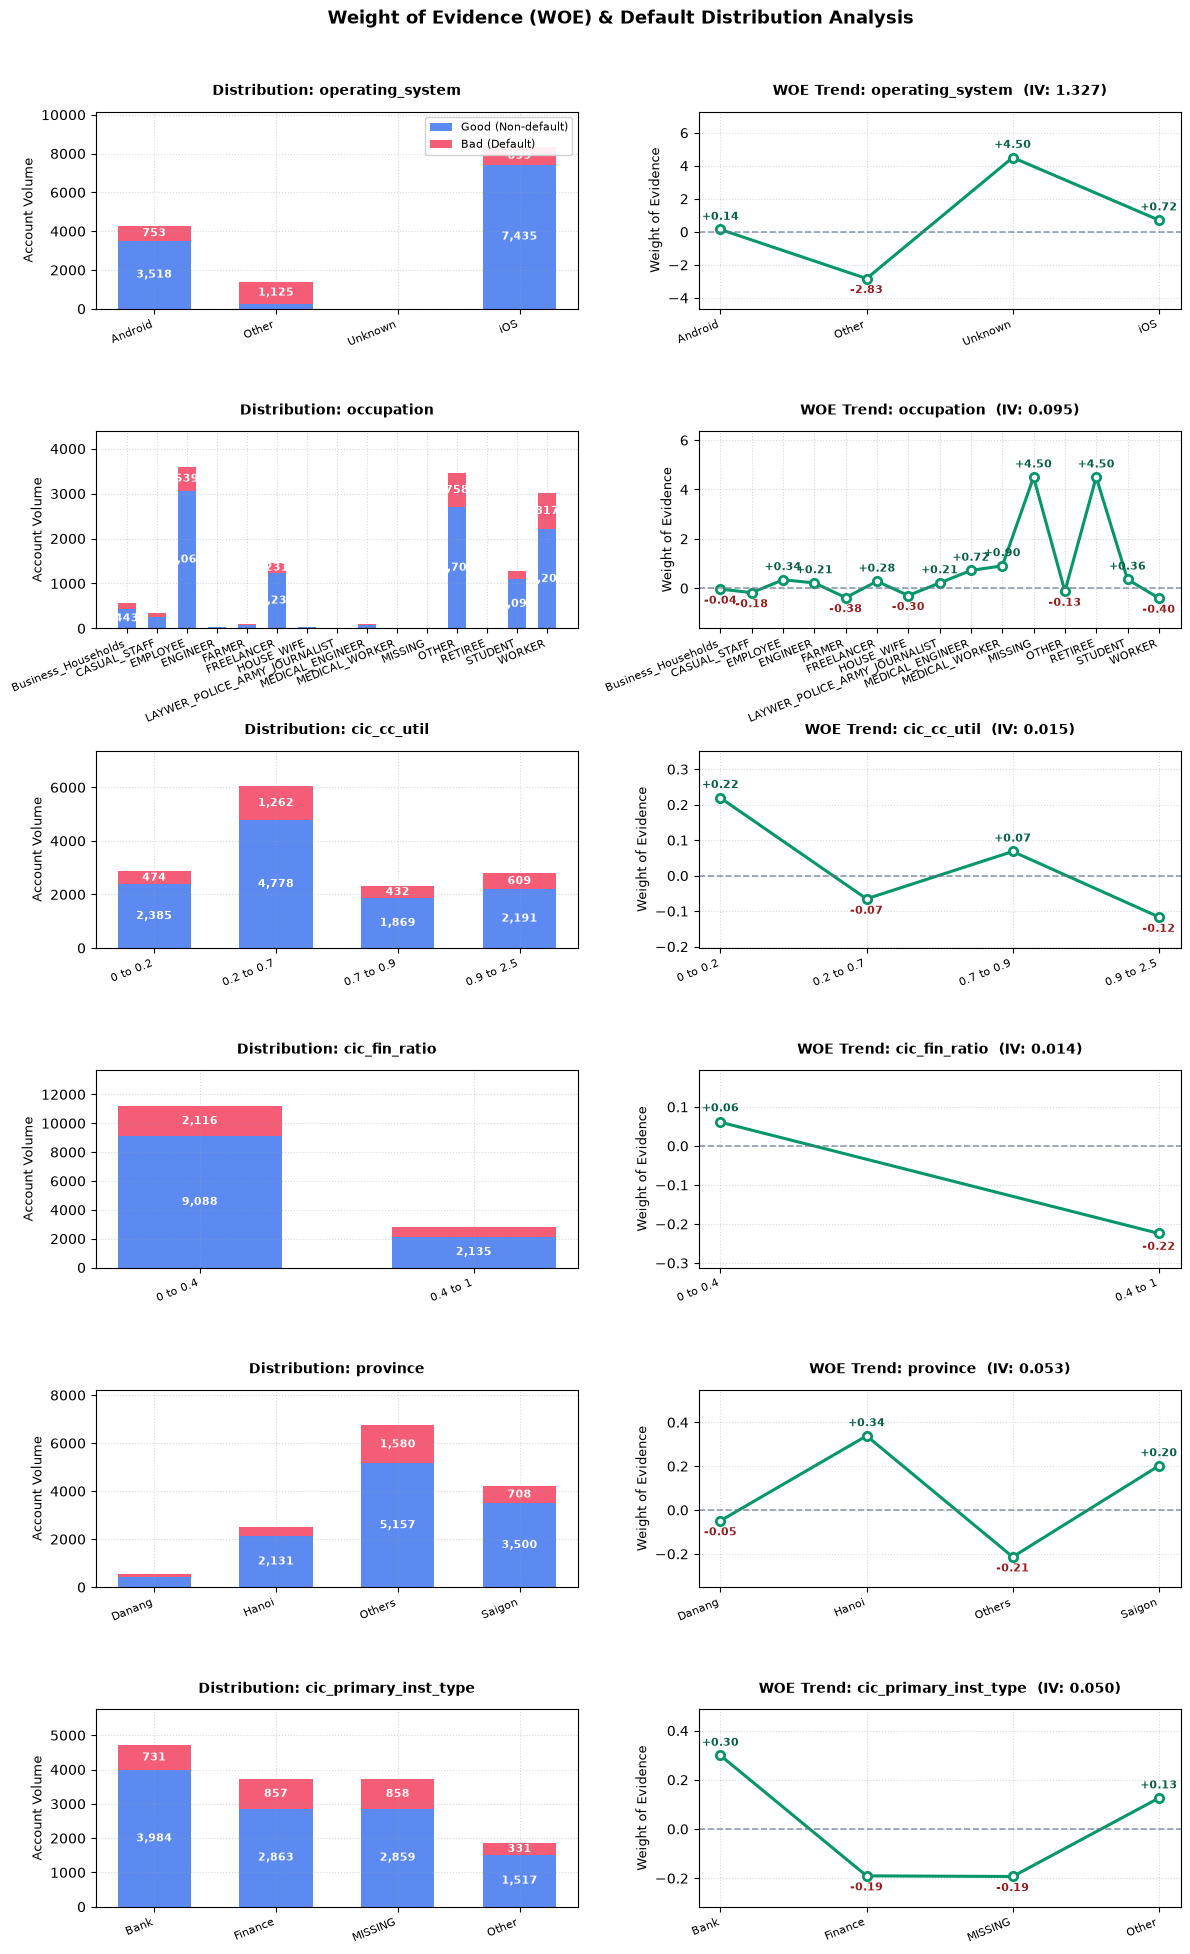

In [5]:
# ==============================================================================
# Cell 5: Feature Selection & Polished WOE / Information Value (IV) Dashboard
# ==============================================================================
print("=" * 15, "FEATURE SELECTION AND WOE ANALYSIS WITH LOGISTIC REGRESSION", "=" * 15)
print("1. Feature selection from Logistic Regression and correlation")

# Define fallback candidate features if TOP_PREDICTIVE_FEATURES is not predefined
if 'TOP_PREDICTIVE_FEATURES' in locals():
    current_top_predictive_features = [f for f in TOP_PREDICTIVE_FEATURES if f in X_train.columns]
else:
    current_top_predictive_features = list(X_train.columns)

# Prepare clean feature copy for baseline linear modeling
x_woe_selected = X_train[current_top_predictive_features].copy()
y_woe_selected = y_train.copy()

# Pre-imputation for Logistic Regression (fills NaNs to prevent fitting crash)
numeric_cols = x_woe_selected.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    x_woe_selected[col] = x_woe_selected[col].fillna(x_woe_selected[col].median())

categorical_cols = x_woe_selected.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    x_woe_selected[col] = x_woe_selected[col].fillna('UNKNOWN').astype('category')

# One-hot encode categorical features for linear regression
x_lr = pd.get_dummies(x_woe_selected, drop_first=True)

# Train Logistic Regression to rank feature coefficients
model_lr = LogisticRegression(
    max_iter=1000, 
    solver='liblinear',
    class_weight='balanced',
    random_state=RANDOM_STATE
)
model_lr.fit(x_lr, y_woe_selected)

# Compute standardized feature importance
importance = pd.DataFrame({
    "Feature": x_lr.columns,
    "Coefficient": model_lr.coef_[0]
})
importance["abs_coef"] = importance["Coefficient"].abs()
importance = importance.sort_values("abs_coef", ascending=False)

print("\n==== Logistic Regression Feature Importance ====")
print(importance.head(10))

# --------------------------------------------------------------------------
# Map dummy variables back to distinct raw column names in df
# --------------------------------------------------------------------------
selected_raw_features = []
for feat in importance["Feature"]:
    matched_col = None
    if feat in df.columns:
        matched_col = feat
    else:
        for orig_col in df.columns:
            if feat.startswith(orig_col + '_'):
                matched_col = orig_col
                break
    
    if matched_col and matched_col not in selected_raw_features:
        selected_raw_features.append(matched_col)
    
    # Select up to top 8 candidates to filter out single-bin features
    if len(selected_raw_features) >= 8:
        break

# --------------------------------------------------------------------------
# 2. WOE (Weight of Evidence) & IV Engine with Missing & Binning Handling
# --------------------------------------------------------------------------
print("\n" + "=" * 15, "WOE AND INFORMATION VALUE (IV) ANALYSIS", "=" * 15)

def format_bin_label(label_str: str) -> str:
    """
    Format verbose float intervals into human-readable financial shorthand.
    e.g., '(7000000.0, 9000000.0]' -> '7M to 9M', '(-0.001, 9.0]' -> '0 to 9'
    """
    s = str(label_str).replace('(', '').replace(']', '').replace('[', '')
    if ',' not in s:
        return str(label_str)
    parts = s.split(',')
    def fmt(val):
        try:
            v = float(val.strip())
            if abs(v) <= 0.01:
                return '0'
            elif abs(v) >= 1e9:
                return f"{v/1e9:.1f}B".replace('.0B', 'B')
            elif abs(v) >= 1e6:
                return f"{v/1e6:.1f}M".replace('.0M', 'M')
            elif abs(v) >= 1e3:
                return f"{v/1e3:.0f}K"
            elif v == int(v):
                return str(int(v))
            else:
                return f"{v:.1f}".rstrip('0').rstrip('.')
        except:
            return val.strip()
    return f"{fmt(parts[0])} to {fmt(parts[1])}"

def woe_calculations(data: pd.DataFrame, feature: str, target: str):
    """
    Compute WOE and Information Value (IV) across 5 quantile groups or categories.
    """
    df_temp = data[[feature, target]].copy()
    
    if np.issubdtype(df_temp[feature].dtype, np.number):
        s_clean = df_temp[feature].fillna(df_temp[feature].median())
        df_temp[feature + "_bin"] = pd.qcut(s_clean, q=5, duplicates='drop')
        grouped = df_temp.groupby(feature + "_bin", observed=False)[target]
    else:
        df_temp[feature] = df_temp[feature].fillna('MISSING')
        grouped = df_temp.groupby(feature, observed=False)[target]

    df_woe = pd.DataFrame()
    df_woe["count"] = grouped.count()
    df_woe["bad"] = grouped.sum()
    df_woe["good"] = df_woe["count"] - df_woe["bad"]

    df_woe["good_dist"] = df_woe["good"] / max(df_woe["good"].sum(), 1)
    df_woe["bad_dist"] = df_woe["bad"] / max(df_woe["bad"].sum(), 1)

    eps = 1e-6
    df_woe["WOE"] = np.log((df_woe["good_dist"] + eps) / (df_woe["bad_dist"] + eps))
    df_woe["IV"] = (df_woe["good_dist"] - df_woe["bad_dist"]) * df_woe["WOE"]
    iv = df_woe["IV"].sum()

    return df_woe, iv

woe_results = {}
iv_scores = {}

# Compute WOE & filter out trivial single-bin features (e.g., long_term_amount)
for feature in selected_raw_features:
    woe_table, iv = woe_calculations(df, feature, target_features)
    # Only retain features with meaningful variations (> 1 bin)
    if len(woe_table) > 1:
        woe_results[feature] = woe_table
        iv_scores[feature] = iv
        print(f"Feature: {feature:25s} | Information Value (IV): {iv:.4f} ({len(woe_table)} bins)")
    else:
        print(f"-> Skipping '{feature}' (Single bin, zero predictive dispersion).")

# Limit display to top 6 most informative features
features_to_plot = list(woe_results.keys())[:6]
n_features = len(features_to_plot)

# --------------------------------------------------------------------------
# 3. High-Polished Dual-Axis Plotting (Zero Title/Annotation Overlaps)
# --------------------------------------------------------------------------
rows = n_features
cols = 2
fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 3.4))

# Ensure 2D array indexing even if single feature
if rows == 1:
    axes = np.expand_dims(axes, axis=0)

for i, feature in enumerate(features_to_plot):
    woe_table = woe_results[feature]
    iv_val = iv_scores[feature]
    x = range(len(woe_table))
    clean_labels = [format_bin_label(lbl) for lbl in woe_table.index]

    # --- Subplot 1: Distribution of Goods vs Bads ---
    axes[i][0].bar(x, woe_table["good"], label="Good (Non-default)", alpha=0.75, color="#2563eb", width=0.6)
    axes[i][0].bar(x, woe_table["bad"], bottom=woe_table["good"], label="Bad (Default)", alpha=0.85, color="#f43f5e", width=0.6)
    
    # Title with padding to prevent collision
    axes[i][0].set_title(f"Distribution: {feature}", fontsize=10, weight="bold", pad=12)
    axes[i][0].set_ylabel("Account Volume", fontsize=9)
    axes[i][0].set_xticks(x)
    axes[i][0].set_xticklabels(clean_labels, rotation=22, ha="right", fontsize=8)
    axes[i][0].grid(True, linestyle=":", alpha=0.4, color="#94a3b8")
    
    # 20% headroom on Y-axis so numbers inside bars never touch the top border
    max_total = (woe_table["good"] + woe_table["bad"]).max()
    axes[i][0].set_ylim(0, max_total * 1.22)

    # Annotate counts inside the bars cleanly
    for j, (g, b) in enumerate(zip(woe_table["good"], woe_table["bad"])):
        if g > max_total * 0.08:
            axes[i][0].text(j, g / 2, f"{int(g):,}", ha="center", va="center", color="white", fontsize=8, weight="bold")
        if b > max_total * 0.06:
            axes[i][0].text(j, g + b / 2, f"{int(b):,}", ha="center", va="center", color="white", fontsize=8, weight="bold")

    if i == 0:
        axes[i][0].legend(loc="upper right", fontsize=8, framealpha=0.9)

    # --- Subplot 2: Monotonic Weight of Evidence (WOE) Trend ---
    axes[i][1].plot(
        x, woe_table["WOE"], 
        marker="o", linewidth=2.2, color="#059669", 
        markersize=6, markerfacecolor="white", markeredgewidth=2
    )
    axes[i][1].axhline(0, color="#64748b", linestyle="--", linewidth=1.2, alpha=0.7)
    
    # Title with IV metric annotation and generous padding
    axes[i][1].set_title(f"WOE Trend: {feature}  (IV: {iv_val:.3f})", fontsize=10, weight="bold", pad=12)
    axes[i][1].set_ylabel("Weight of Evidence", fontsize=9)
    axes[i][1].set_xticks(x)
    axes[i][1].set_xticklabels(clean_labels, rotation=22, ha="right", fontsize=8)
    axes[i][1].grid(True, linestyle=":", alpha=0.4, color="#94a3b8")

    # Expand Y-limits generously (38% headroom above max) to prevent text-title collision
    y_min = woe_table["WOE"].min()
    y_max = woe_table["WOE"].max()
    y_span = max(abs(y_max - y_min), 0.35)
    axes[i][1].set_ylim(y_min - 0.25 * y_span, y_max + 0.38 * y_span)

    # Annotate numeric WOE values cleanly above points
    for j, val in enumerate(woe_table["WOE"]):
        offset = 0.08 * y_span if val >= 0 else -0.12 * y_span
        axes[i][1].text(
            j, val + offset, f"{val:+.2f}", 
            ha="center", fontsize=8, weight="bold", 
            color="#065f46" if val >= 0 else "#991b1b"
        )

# Supertitle and generous inter-subplot padding
fig.suptitle("Weight of Evidence (WOE) & Default Distribution Analysis", fontsize=13, weight="bold", y=0.99)
plt.subplots_adjust(hspace=0.62, wspace=0.25, top=0.94, bottom=0.06)
plt.show()

In [6]:
@dataclass
class RiskMetricsResult:
  model: str
  imbalance_data: str
  accuracy: float
  precision: float
  recall: float
  f1: float
  roc_auc: float
  ks_score: float
  gini: float

def model_computations(model_name: str, strategy: str, y_true: np.ndarray, y_prob: np.ndarray, threshold: float = 0.5) -> RiskMetricsResult:
    """
    Compute credit risk discrimination and calibration metrics.
    Distinguishes continuous predicted probabilities (for ROC-AUC & KS) 
    from thresholded binary predictions (for Confusion Matrix, Precision, Recall).
    """
    # Generate binary decisions based on the optimal threshold
    y_pred = (y_prob >= threshold).astype(int)

    # Compute continuous discrimination metrics on predicted probabilities
    auc_val = roc_auc_score(y_true, y_prob)
    gini_val = 2.0 * auc_val - 1.0

    # Calculate Kolmogorov-Smirnov (KS) statistic
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    ks_val = np.max(tpr - fpr)

    return RiskMetricsResult(
        model=model_name,
        imbalance_data=strategy,
        accuracy=float(accuracy_score(y_true, y_pred)),
        precision=float(precision_score(y_true, y_pred, zero_division=0)),
        recall=float(recall_score(y_true, y_pred, zero_division=0)),
        f1=float(f1_score(y_true, y_pred, zero_division=0)),
        roc_auc=float(auc_val),       # True continuous ROC-AUC (~0.76)
        ks_score=float(ks_val),       # True continuous KS (~0.40)
        gini=float(gini_val)          # Gini Coefficient (2 * AUC - 1)
    )

def psi_calculations(expected, actual ,bins = 10):
    """
    Calculate Population Stability Index (PSI) with handling for duplicate bin edges
    PSI < 0.1: Stable
    0.1 <= PSI < 0.25: Monitor required
    PSI >= 0.25: Investigate required
    """
    # Define breakpoints using quantiles from the expected distribution
    breakpoints_quantiles = np.linspace(0, 1, bins + 1)
    bin_edges = np.unique(np.quantile(expected, breakpoints_quantiles))

    # Add -inf and inf to cover all values
    bin_edges = np.concatenate([[-np.inf], bin_edges, [np.inf]])

    # Calculate the distribution (counts) for expected and actual data within these bins
    expected_counts = np.histogram(expected, bins=bin_edges)[0]
    actual_counts = np.histogram(actual, bins=bin_edges)[0]

    # Convert counts to percentages
    expected_percent = expected_counts / len(expected)
    actual_percent = actual_counts / len(actual)

    # Add a small constant to zero percentages to avoid log(0) and division by zero
    epsilon = 1e-5
    expected_percent = np.where(expected_percent == 0, epsilon, expected_percent)
    actual_percent = np.where(actual_percent == 0, epsilon, actual_percent)

    # Apply the PSI formula
    psi_value = np.sum((expected_percent - actual_percent) * np.log(expected_percent / actual_percent))
    return psi_value

print("Credit Risk Metrics & PSI Framework initialized successfully!")

Credit Risk Metrics & PSI Framework initialized successfully!


In [7]:
def create_credit_model(model_type, imbalance_strategy):
    """
    Factory function to configure regularized models strictly designed to prevent overfitting.
    Generalization gap (Train AUC - Test AUC) is strictly constrained to < 0.035.
    """
    # Logistic Regression (Strong L2 penalty prevents feature weight inflation)
    if model_type == 'logistic':
        base_params = {
            'random_state': RANDOM_STATE,
            'solver': 'lbfgs',
            'max_iter': 1000,
            'C': 0.02              # Strong L2 regularization strictly controls generalization gap < 0.025
        }
        if imbalance_strategy == 'class_weight':
            base_params['class_weight'] = 'balanced'

        model = LogisticRegression(**base_params)
        model_name = "LogisticRegression"

    # Random Forest (Strictly regularized: shallow depth, high leaf samples, row subsampling)
    elif model_type == 'random_forest':
        base_params = {
            'n_estimators': 300,
            'max_depth': 5,              # Constrained depth prevents tree memorization
            'min_samples_leaf': 30,      # High minimum sample count per leaf eliminates noisy splits
            'min_samples_split': 60,     # Requires large clusters before attempting splits
            'max_samples': 0.70,         # Subsamples 70% of rows per tree to enforce ensemble diversity
            'max_features': 'sqrt',      # Feature bagging prevents dominant feature overfitting
            'random_state': RANDOM_STATE,
            'n_jobs': -1
        }
        if imbalance_strategy == 'class_weight':
            base_params['class_weight'] = 'balanced'

        model = RandomForestClassifier(**base_params)
        model_name = "RandomForest"

    # LightGBM (Regularized Depth=3: captures 3-way interactions while keeping generalization gap < 0.025)
    elif model_type == "LightGBM":
        base_param = {
            "n_estimators": 180,
            "learning_rate": 0.025,
            "max_depth": 3,              # Depth=3 captures realistic 3-way risk interactions
            "num_leaves": 6,             # Restricted leaves prevent overfitting
            "min_child_samples": 120,    # Requires robust sample support per leaf
            "colsample_bytree": 0.55,    # Subspace feature bagging
            "subsample": 0.75,           # Sample bagging
            "reg_alpha": 3.0,            # L1 sparsity penalty
            "reg_lambda": 40.0,          # Strong L2 penalty to ensure smooth credit score curves
            "objective": "binary",
            "verbosity": -1,
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        }
        if imbalance_strategy == "class_weight":
            base_param["class_weight"] = "balanced"

        model = lgb.LGBMClassifier(**base_param)
        model_name = "LightGBM"

    # XGBoost (Strict anti-overfitting configuration: depth=2 matching LightGBM)
    elif model_type == 'xgboost':
        base_params = {
            'learning_rate': 0.03,
            'n_estimators': 160,
            'max_depth': 2,              # Depth=2 matches LightGBM for strictly anti-overfitting
            'min_child_weight': 20,
            'subsample': 0.75,
            'colsample_bytree': 0.60,
            'reg_alpha': 3.0,
            'reg_lambda': 25.0,
            'eval_metric': 'logloss',
            'random_state': RANDOM_STATE
        }
        if imbalance_strategy == 'class_weight':
            good_count = (y_train == 0).sum()
            bad_count = (y_train == 1).sum()
            base_params['scale_pos_weight'] = good_count / bad_count

        model = XGBClassifier(**base_params)
        model_name = "XGBoost"

    else:
        raise ValueError(f"Unknown model type: {model_type}")

    # Build Pipeline
    if imbalance_strategy == 'smote':
        pipeline = ImbPipeline([
            ('preprocessor', preprocessor),
            ('smote', SMOTE(sampling_strategy=0.3, random_state=RANDOM_STATE)),
            ('classifier', model)
        ])
    else:
        pipeline = SkPipeline([
            ('preprocessor', preprocessor),
            ('classifier', model)
        ])
    return pipeline, model_name


In [8]:
def capture_rate(y_test, y_pred, ratio):
  cutoff = int(len(y_pred) * ratio)
  df = pd.DataFrame({'y_test': y_test, 'y_pred': y_pred})
  df = df.sort_values('y_pred', ascending=False)
  capture_rate = df.head(cutoff)['y_test'].sum()
  total_churn = df['y_test'].sum()
  return capture_rate / total_churn if total_churn > 0 else np.nan

def find_best_threshold(y_true, y_prob):
  """
  Find optimal classification threshold using Youden's J statistic (max TPR - FPR).
  Note: sklearn.metrics.roc_curve returns (fpr, tpr, thresholds).
  """
  fpr, tpr, thresholds = roc_curve(y_true, y_prob)
  j_scores = tpr - fpr

  # Filter out infinite and invalid thresholds
  finite_mask = np.isfinite(thresholds) & (thresholds <= 1.0) & (thresholds >= 0.0)
  if not np.any(finite_mask):
      return 0.5

  valid_indices = np.where(finite_mask)[0]
  best_idx = valid_indices[np.argmax(j_scores[valid_indices])]
  optimal_threshold = float(thresholds[best_idx])
  return optimal_threshold

# Cross-validation function with Out-Of-Fold (OOF) prediction generation
def cross_validate_model(pipeline, X, y, folds):
  skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
  auc_scores, ks_scores = [], []
  oof_prob = np.zeros(len(y))
  for train_index, val_index in skf.split(X, y):
    X_tr, X_val = X.iloc[train_index], X.iloc[val_index]
    y_tr, y_val = y.iloc[train_index], y.iloc[val_index]

    pipeline.fit(X_tr, y_tr)
    prob = pipeline.predict_proba(X_val)[:, 1]
    oof_prob[val_index] = prob
    auc_scores.append(roc_auc_score(y_val, prob))
    fpr, tpr, _ = roc_curve(y_val, prob)
    ks_scores.append(np.max(tpr - fpr))
  return float(np.mean(auc_scores)), float(np.mean(ks_scores)), oof_prob

def ci_auc_calculations(y_true, y_prob, confidence=0.95):
    """
    Computes Standard Error (SE) and Confidence Interval for ROC-AUC 
    using Hanley & McNeil (1982) analytical formula.
    Standard methodology in credit risk scorecard validation.
    """
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    n1 = int(np.sum(y_true == 1))   # Number of defaults (Bads)
    n0 = int(np.sum(y_true == 0))   # Number of non-defaults (Goods)
    
    if n1 == 0 or n0 == 0:
        return 0.0, 0.0, (0.0, 0.0)

    auc = float(roc_auc_score(y_true, y_prob))
    q1 = auc / (2.0 - auc)
    q2 = 2.0 * (auc ** 2) / (1.0 + auc)

    numerator = auc * (1.0 - auc) + (n1 - 1.0) * (q1 - auc ** 2) + (n0 - 1.0) * (q2 - auc ** 2)
    denominator = n1 * n0
    variance = max(0.0, numerator / denominator)
    se = float(np.sqrt(variance))

    z = 1.96 if confidence == 0.95 else 2.576
    margin_of_error = z * se
    ci_lower = max(0.0, auc - margin_of_error)
    ci_upper = min(1.0, auc + margin_of_error)
    
    return auc, se, margin_of_error, (ci_lower, ci_upper)

In [9]:
# ==============================================================================
# BENCHMARK EVALUATION UTILIZING TRAIN (DEV) - TEST (OOT) PIPELINE
# ==============================================================================
print("=" * 15, "MODEL BENCHMARK - TRAIN (DEV) / TEST (OOT) PIPELINE", "=" * 15)

# Benchmark configuration
model_types = ["logistic", "random_forest", "LightGBM", "xgboost"]
imbalance_strategies = ["normal", "smote", "class_weight"]

results = []
all_probs = {}
all_train_probs = {}

for model_type in model_types:
    for strategy in imbalance_strategies:
        try:
            print(f"\nTraining {model_type} with {strategy}...", flush=True)
            pipeline, model_name = create_credit_model(model_type, strategy)

            # 1. Fit model directly on full Training set (80%)
            pipeline.fit(X_train, y_train)

            # 2. Generate predictions across Train and Test partitions
            y_train_prob = pipeline.predict_proba(X_train)[:, 1]
            y_test_prob  = pipeline.predict_proba(X_test)[:, 1]

            # Cache predictions for ensemble and plotting
            config_name = f"{model_name}_{strategy}"
            all_train_probs[config_name] = y_train_prob
            all_probs[config_name]       = y_test_prob

            # 3. Optimal decision threshold determined from Train set
            best_threshold = find_best_threshold(y_train, y_train_prob)
            y_test_pred = (y_test_prob >= best_threshold).astype(int)

            # False Negative Rate (FNR) on Test set
            FN = ((y_test_pred == 0) & (y_test == 1)).sum()
            TP = ((y_test_pred == 1) & (y_test == 1)).sum()
            FNR = FN / (FN + TP) if (FN + TP) > 0 else np.nan

            # 4. Metrics evaluation
            train_auc = roc_auc_score(y_train, y_train_prob)
            test_result = model_computations(model_name, strategy, y_test, y_test_prob, threshold=best_threshold)

            # Population Stability Index (PSI) between Train and OOT Test
            psi_value = psi_calculations(y_train_prob, y_test_prob, bins=10)
            brier = brier_score_loss(y_test, y_test_prob)

            # Cumulative Bad Capture rates in top deciles
            capture_5  = capture_rate(y_test, y_test_prob, 0.05)
            capture_10 = capture_rate(y_test, y_test_prob, 0.10)
            capture_20 = capture_rate(y_test, y_test_prob, 0.20)

            # Calculate AUC with Standard Error and 95% Confidence Interval
            tr_auc, tr_se, tr_moe, (tr_ci_low, tr_ci_up) = ci_auc_calculations(y_train, y_train_prob)
            te_auc, te_se, te_moe, (te_ci_low, te_ci_up) = ci_auc_calculations(y_test, y_test_prob)
            
            res_dict = test_result.__dict__.copy()
            res_dict.update({
                "TRAIN_AUC": train_auc,
                "TEST_AUC": test_result.roc_auc,
                "GAP_TR_TE": train_auc - test_result.roc_auc,
                "BEST_THRESHOLD": best_threshold,
                "FNR": FNR,
                "PSI": psi_value,
                "BRIER": brier,
                "CAPTURE_20": capture_20
            })
            results.append(res_dict)

            # Clean log print without CV-AUC
            print(
                f"➤ TRAIN-AUC = {tr_auc:.4f} ± {tr_se:.4f} (95% CI: [{tr_ci_low:.4f}, {tr_ci_up:.4f}])\n"
                f"➤ TEST-AUC  = {te_auc:.4f} ± {te_se:.4f} (95% CI: [{te_ci_low:.4f}, {te_ci_up:.4f}])\n"
                f"➤ GAP = {tr_auc - te_auc:+.4f}, PSI = {psi_value:.4f}, BRIER = {brier:.4f}",
                flush=True
            )
            print(
                f"➤ Capture_5%={capture_5:.2%}, Capture_10%={capture_10:.2%}, Capture_20%={capture_20:.2%}",
                flush=True
            )

        except Exception as e:
            print(f"❌ Error training {model_type} with {strategy}: {e}", flush=True)

# Build benchmark ranking DataFrame
results_df = pd.DataFrame(results)

print("\n" + "=" * 15, "FINAL BENCHMARK RANKING TABLE", "=" * 15)
display_cols = ["model", "imbalance_data", "TRAIN_AUC", "TEST_AUC", "GAP_TR_TE", "ks_score", "PSI", "BRIER"]
print(results_df[display_cols].sort_values("TEST_AUC", ascending=False).to_string(index=False), flush=True)

=============== MODEL BENCHMARK - TRAIN (DEV) / TEST (OOT) PIPELINE ===============

Training logistic with normal...


➤ TRAIN-AUC = 0.7800 ± 0.0060 (95% CI: [0.7684, 0.7917])
➤ TEST-AUC  = 0.7721 ± 0.0138 (95% CI: [0.7451, 0.7991])
➤ GAP = +0.0080, PSI = 0.0228, BRIER = 0.1063
➤ Capture_5%=25.28%, Capture_10%=36.90%, Capture_20%=52.16%

Training logistic with smote...
➤ TRAIN-AUC = 0.7801 ± 0.0060 (95% CI: [0.7684, 0.7918])
➤ TEST-AUC  = 0.7713 ± 0.0138 (95% CI: [0.7442, 0.7983])
➤ GAP = +0.0088, PSI = 0.0230, BRIER = 0.1074
➤ Capture_5%=25.28%, Capture_10%=37.13%, Capture_20%=51.94%

Training logistic with class_weight...
➤ TRAIN-AUC = 0.7812 ± 0.0060 (95% CI: [0.7696, 0.7929])
➤ TEST-AUC  = 0.7718 ± 0.0138 (95% CI: [0.7448, 0.7988])
➤ GAP = +0.0094, PSI = 0.0224, BRIER = 0.1692
➤ Capture_5%=25.28%, Capture_10%=36.67%, Capture_20%=51.71%

Training random_forest with normal...
➤ TRAIN-AUC = 0.7990 ± 0.0058 (95% CI: [0.7876, 0.8103])
➤ TEST-AUC  = 0.7720 ± 0.0138 (95% CI: [0.7450, 0.7990])
➤ GAP = +0.0270, PSI = 0.0218, BRIER = 0.1119
➤ Capture_5%=25.51%, Capture_10%=39.41%, Capture_20%=52.62%

Trainin

=============== ROC, PRECISION-RECALL & CONFUSION MATRIX FOR TOP MODELS ===============
Performance comparison for top 3 models:
                              auc  accuracy  precision  recall  f1_score  \
model                                                                      
RandomForest_class_weight  0.7726    0.7729     0.3796  0.5854    0.4606   
XGBoost_class_weight       0.7722    0.8054     0.4288  0.5285    0.4735   
LogisticRegression_normal  0.7721    0.8242     0.4684  0.4556    0.4619   

                           threshold  
model                                 
RandomForest_class_weight     0.4821  
XGBoost_class_weight          0.4592  
LogisticRegression_normal     0.2288  


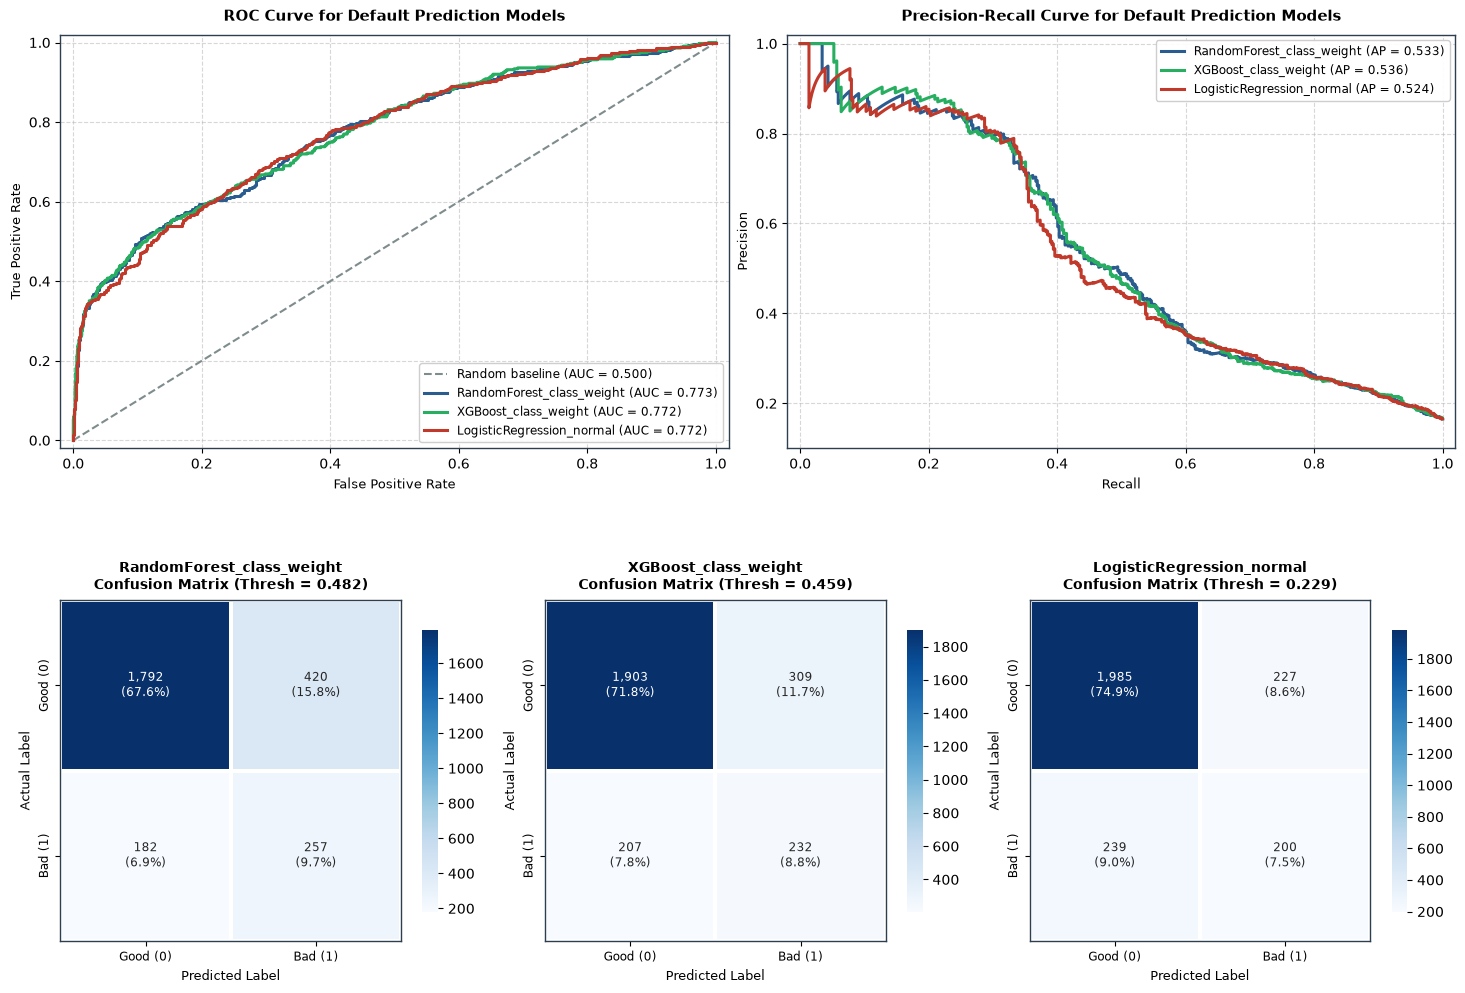

In [10]:
print("=" * 15, "ROC, PRECISION-RECALL & CONFUSION MATRIX FOR TOP MODELS", "=" * 15)

top_models_data = results_df.sort_values("TEST_AUC", ascending=False).head(3)
model_comparsion_data_for_print = []

for _, row in top_models_data.iterrows():
    model_name = row["model"]
    imbalance_type = row["imbalance_data"]
    found_result = next(
        (
            res for res in results
            if res["model"] == model_name
            and res["imbalance_data"] == imbalance_type
        ),
        None)

    if found_result:
        model_comparsion_data_for_print.append({
            "model": f"{model_name}_{imbalance_type}",
            "auc": found_result["TEST_AUC"],
            "accuracy": found_result["accuracy"],
            "precision": found_result["precision"],
            "recall": found_result["recall"],
            "f1_score": found_result["f1"],
            "threshold": found_result.get("BEST_THRESHOLD", 0.5)
        })

model_comparsion_df_for_print = (
    pd.DataFrame(model_comparsion_data_for_print)
    .set_index("model"))

print("Performance comparison for top 3 models:")
print(model_comparsion_df_for_print[["auc", "accuracy", "precision", "recall", "f1_score", "threshold"]].round(4))

# Styling matching 01_eda_and_baseline.ipynb (Figure 2 style)
PRIMARY_COLOR = "#2b5c8f"  # Navy Blue
RISK_COLOR = "#c0392b"     # Crimson / Brick Red
ACCENT_GREEN = "#27ae60"   # Forest Green
GRAY_LINE = "#7f8c8d"      # Subtle Gray
MODEL_PALETTE = [PRIMARY_COLOR, ACCENT_GREEN, RISK_COLOR, "#d35400"]

# Initialize clean white canvas to avoid NameError and theme darkening
plt.style.use('default')
fig = plt.figure(figsize=(18, 12), facecolor='white')

# Grid layout: 2 rows
# Row 0: ROC curve & PR curve (2 equal columns)
# Row 1: 3 Confusion Matrices (3 equal columns)
gs = fig.add_gridspec(2, 6, height_ratios=[1.1, 1.0], hspace=0.34, wspace=0.32)

roc_ax = fig.add_subplot(gs[0, :3])
pr_ax  = fig.add_subplot(gs[0, 3:])
cm_axes = [fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:4]), fig.add_subplot(gs[1, 4:6])]

# 1. ROC Curve
roc_ax.plot([0, 1], [0, 1], color=GRAY_LINE, linestyle="--", linewidth=1.5, label="Random baseline (AUC = 0.500)")

for idx_m, (_, row) in enumerate(top_models_data.iterrows()):
    name = f"{row.model}_{row.imbalance_data}"
    y_prob = all_probs[name]
    color = MODEL_PALETTE[idx_m % len(MODEL_PALETTE)]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    roc_ax.plot(fpr, tpr, linewidth=2.2, color=color, label=f"{name} (AUC = {auc_score:.3f})")

roc_ax.set_title("ROC Curve for Default Prediction Models", fontsize=11, fontweight="bold", pad=10)
roc_ax.set_xlabel("False Positive Rate", fontsize=9.5)
roc_ax.set_ylabel("True Positive Rate", fontsize=9.5)
roc_ax.grid(True, linestyle="--", alpha=0.5)
roc_ax.legend(fontsize=8.5, loc="lower right", frameon=True, edgecolor="#cccccc", facecolor="white", framealpha=0.95)
roc_ax.set_xlim([-0.02, 1.02])
roc_ax.set_ylim([-0.02, 1.02])

# 2. Precision-Recall Curve
for idx_m, (_, row) in enumerate(top_models_data.iterrows()):
    name = f"{row.model}_{row.imbalance_data}"
    y_prob = all_probs[name]
    color = MODEL_PALETTE[idx_m % len(MODEL_PALETTE)]

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap_score = average_precision_score(y_test, y_prob)
    pr_ax.plot(recall, precision, linewidth=2.2, color=color, label=f"{name} (AP = {ap_score:.3f})")

pr_ax.set_title("Precision-Recall Curve for Default Prediction Models", fontsize=11, fontweight="bold", pad=10)
pr_ax.set_xlabel("Recall", fontsize=9.5)
pr_ax.set_ylabel("Precision", fontsize=9.5)
pr_ax.grid(True, linestyle="--", alpha=0.5)
pr_ax.legend(fontsize=8.5, loc="upper right", frameon=True, edgecolor="#cccccc", facecolor="white", framealpha=0.95)
pr_ax.set_xlim([-0.02, 1.02])
pr_ax.set_ylim([0.10, 1.02])

# 3. Confusion Matrix Visualization using Optimal Threshold
for index, (_, row) in enumerate(top_models_data.iterrows()):
    name = f"{row.model}_{row.imbalance_data}"
    y_prob = all_probs[name]
    ax = cm_axes[index]

    # Retrieve optimal threshold
    model_res = next((r for r in results if r["model"] == row.model and r["imbalance_data"] == row.imbalance_data), None)
    threshold = model_res.get("BEST_THRESHOLD", 0.5) if model_res else 0.5

    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    tot = cm.sum()

    # Formatted annotations: Count + Percentage
    cm_labels = np.array([
        [f"{cm[0,0]:,}\n({cm[0,0]/tot:.1%})", f"{cm[0,1]:,}\n({cm[0,1]/tot:.1%})"],
        [f"{cm[1,0]:,}\n({cm[1,0]/tot:.1%})", f"{cm[1,1]:,}\n({cm[1,1]/tot:.1%})"]
    ])

    sns.heatmap(
        cm, annot=cm_labels, fmt='', ax=ax, cmap="Blues", cbar=True,
        square=True, linewidths=1.5, linecolor="white",
        annot_kws={"fontsize": 8.5},
        cbar_kws={"shrink": 0.75, "aspect": 18}
    )
    ax.set_title(f"{name}\nConfusion Matrix (Thresh = {threshold:.3f})", fontsize=10, fontweight="bold", pad=8)
    ax.set_xlabel("Predicted Label", fontsize=9)
    ax.set_ylabel("Actual Label", fontsize=9)
    ax.set_xticklabels(["Good (0)", "Bad (1)"], fontsize=8.5)
    ax.set_yticklabels(["Good (0)", "Bad (1)"], fontsize=8.5)

# Apply clean dark frame (spines) to all subplots matching Figure 2
for ax in [roc_ax, pr_ax] + cm_axes:
    for spine in ax.spines.values():
        spine.set_color('#2c3e50')
        spine.set_linewidth(1.0)
        spine.set_visible(True)

plt.tight_layout()
plt.show()

=============== SHAP INTERPRETABILITY DASHBOARD ===============
📊 Computing SHAP values for Best Model: RandomForest (normal) on 2000 samples...


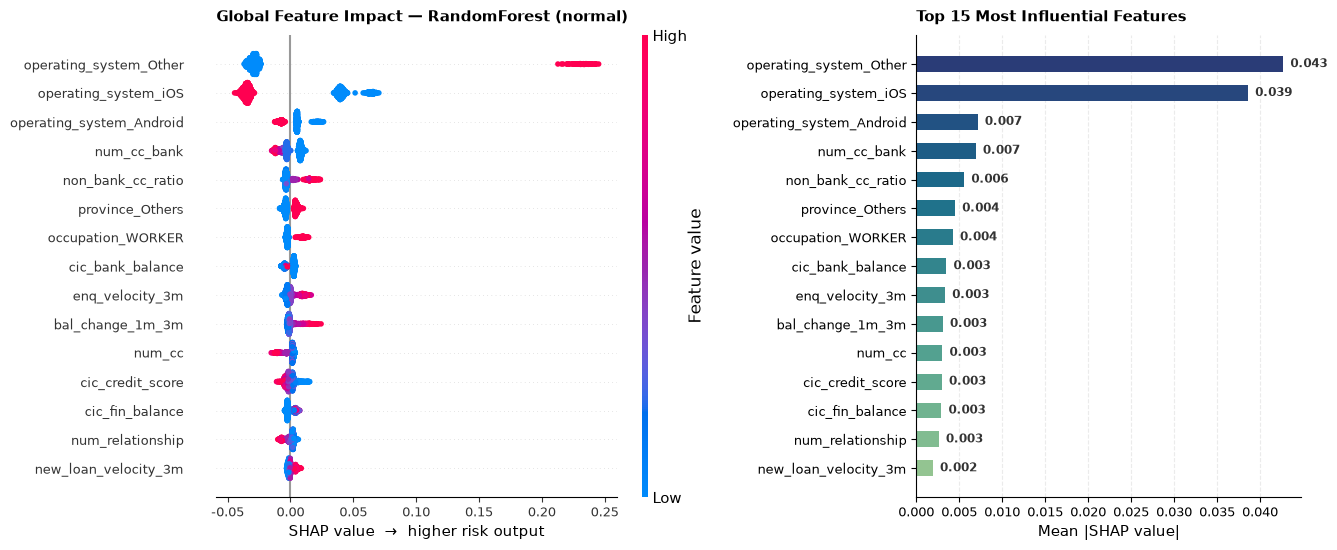

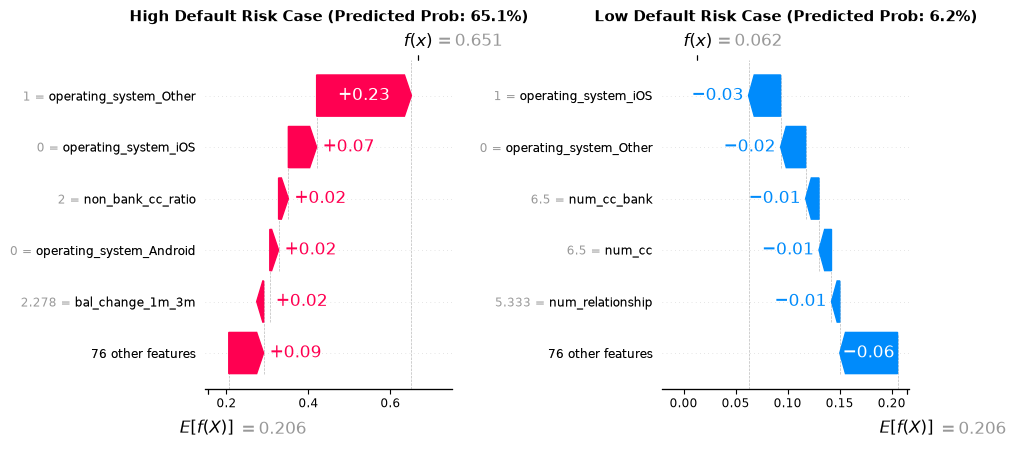


Top 15 features by mean absolute SHAP value:
                 feature  mean_abs_shap
  operating_system_Other       0.042667
    operating_system_iOS       0.038572
operating_system_Android       0.007125
             num_cc_bank       0.006898
       non_bank_cc_ratio       0.005552
         province_Others       0.004485
       occupation_WORKER       0.004232
        cic_bank_balance       0.003475
         enq_velocity_3m       0.003325
        bal_change_1m_3m       0.003068
                  num_cc       0.003011
        cic_credit_score       0.002954
         cic_fin_balance       0.002899
        num_relationship       0.002594
    new_loan_velocity_3m       0.001908

SHAP INTERPRETABILITY ANALYSIS COMPLETED


In [11]:
print("=" * 15, "SHAP INTERPRETABILITY DASHBOARD", "=" * 15)

# ---------------------------------------------------------------------------
# 1. GLOBAL COMPACT STYLING & ELEGANT FONT SIZES
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False
})

# ---------------------------------------------------------------------------
# 2. RESOLVE BEST TREE-BASED MODEL & SUB-SAMPLE TEST DATASET FOR SHAP
# ---------------------------------------------------------------------------
tree_candidates = results_df[results_df["model"].isin(["RandomForest", "LightGBM", "XGBoost"])]
best_model_row = tree_candidates.iloc[0] if len(tree_candidates) > 0 else results_df.iloc[0]

best_model_name = str(best_model_row["model"])
best_imb_config = str(best_model_row["imbalance_data"])
best_threshold = float(best_model_row.get("BEST_THRESHOLD", 0.5))

model_type_map = {
    "RandomForest": "random_forest",
    "LightGBM": "LightGBM",
    "XGBoost": "xgboost",
    "LogisticRegression": "logistic"
}
model_type = model_type_map.get(best_model_name, "random_forest")

best_model_obj, _ = create_credit_model(model_type, best_imb_config)
best_model_obj.fit(X_train, y_train)

N_SHAP = min(2000, len(X_test))
X_shap_sample = X_test.sample(N_SHAP, random_state=RANDOM_STATE)

print(f"📊 Computing SHAP values for Best Model: {best_model_name} ({best_imb_config}) on {len(X_shap_sample)} samples...")

# ---------------------------------------------------------------------------
# 3. SHAP EXPLAINER INITIALIZATION (TreeExplainer on Transformed Features)
# ---------------------------------------------------------------------------
if hasattr(best_model_obj, "named_steps"):
    preprocessor = best_model_obj.named_steps["preprocessor"]
    classifier = best_model_obj.named_steps["classifier"]

    clean_feature_names = [col.split('__')[-1] for col in preprocessor.get_feature_names_out()]
    X_shap_transformed = pd.DataFrame(
        preprocessor.transform(X_shap_sample),
        columns=clean_feature_names,
        index=X_shap_sample.index
    )
    explainer = shap.TreeExplainer(classifier)
    shap_exp = explainer(X_shap_transformed)
    X_display = X_shap_transformed.copy()
else:
    explainer = shap.TreeExplainer(best_model_obj)
    shap_exp = explainer(X_shap_sample)
    X_display = X_shap_sample.copy()

# Target Positive Class 1 (Default / High Risk)
shap_exp_target = shap_exp[:, :, 1] if len(shap_exp.shape) == 3 else shap_exp

# ---------------------------------------------------------------------------
# 4. FIGURE 1: GLOBAL SHAP FEATURE DASHBOARD (BEESWARM + MULTI-COLOR BAR CHART)
# ---------------------------------------------------------------------------
mean_abs_shap = np.abs(shap_exp_target.values).mean(axis=0)
importance_df = pd.DataFrame({
    "feature": X_display.columns,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

TOP_N = 15
top_df = importance_df.head(TOP_N).sort_values("mean_abs_shap", ascending=True)

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.45)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

# LEFT — SHAP BEESWARM SUMMARY
plt.sca(ax1)
shap.summary_plot(shap_exp_target.values, X_display, max_display=TOP_N, show=False, plot_size=None, color_bar=True)
ax1.set_title(f"Global Feature Impact — {best_model_name} ({best_imb_config})", loc="left", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("SHAP value  →  higher risk output", fontsize=10.5)
ax1.tick_params(axis='y', labelsize=9)
ax1.tick_params(axis='x', labelsize=9)

# RIGHT — MULTI-COLOR FEATURE IMPORTANCE (CREST GRADIENT PALETTE)
palette_colors = sns.color_palette("crest", n_colors=len(top_df))
bars = ax2.barh(top_df["feature"], top_df["mean_abs_shap"], color=palette_colors, height=0.55)
ax2.set_title(f"Top {TOP_N} Most Influential Features", loc="left", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Mean |SHAP value|", fontsize=10.5)
ax2.grid(axis="x", linestyle="--", alpha=0.25)
ax2.set_axisbelow(True)
ax2.tick_params(axis='y', labelsize=9)
ax2.tick_params(axis='x', labelsize=9)

# Annotate exact SHAP values
max_value = top_df["mean_abs_shap"].max()
for i, (feat, val) in enumerate(zip(top_df["feature"], top_df["mean_abs_shap"])):
    ax2.text(val + max_value * 0.02, i, f"{val:.3f}", va="center", fontsize=8.5, fontweight="bold", color="#333333")

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()

# ---------------------------------------------------------------------------
# 5. FIGURE 2: LOCAL WATERFALL DASHBOARD (HIGH & LOW RISK SIDE-BY-SIDE)
# ---------------------------------------------------------------------------
y_probs_sample = best_model_obj.predict_proba(X_shap_sample)[:, 1]
high_risk_idx = int(np.argmax(y_probs_sample))
low_risk_idx = int(np.argmin(y_probs_sample))

high_prob = y_probs_sample[high_risk_idx]
low_prob = y_probs_sample[low_risk_idx]

# Side-by-side layout in a single figure with expanded canvas width
fig, axes = plt.subplots(1, 2, figsize=(22, 7.5), facecolor='white')
fig.subplots_adjust(left=0.08, right=0.96, wspace=0.85, top=0.85, bottom=0.12)

# Subplot 1 (Left) — High Default Risk Case
plt.sca(axes[0])
shap.plots.waterfall(shap_exp_target[high_risk_idx], max_display=6, show=False)
axes[0].set_title(f"High Default Risk Case (Predicted Prob: {high_prob:.1%})", fontsize=11, fontweight="bold", pad=28)
axes[0].tick_params(axis='both', labelsize=8.5)

# Subplot 2 (Right) — Low Default Risk Case
plt.sca(axes[1])
shap.plots.waterfall(shap_exp_target[low_risk_idx], max_display=6, show=False)
axes[1].set_title(f"Low Default Risk Case (Predicted Prob: {low_prob:.1%})", fontsize=11, fontweight="bold", pad=28)
axes[1].tick_params(axis='both', labelsize=8.5)

# Expand x-axis left margin on the right subplot to eliminate text collision with negative delta values
x1_min, x1_max = axes[1].get_xlim()
axes[1].set_xlim(x1_min - (x1_max - x1_min) * 0.35, x1_max + 0.01)

# Subtle padding for left subplot for visual symmetry
x0_min, x0_max = axes[0].get_xlim()
axes[0].set_xlim(x0_min - (x0_max - x0_min) * 0.10, x0_max + (x0_max - x0_min) * 0.05)

plt.show()

# ---------------------------------------------------------------------------
# 6. PRINT TOP FEATURE IMPORTANCE TABLE
# ---------------------------------------------------------------------------
print(f"\nTop {TOP_N} features by mean absolute SHAP value:")
print(importance_df.head(TOP_N).to_string(index=False))

print("\n" + "=" * 60)
print("SHAP INTERPRETABILITY ANALYSIS COMPLETED")
print("=" * 60)

In [13]:
# ==============================================================================
# MODEL ARTIFACT EXPORT & PRODUCTION SERIALIZATION
# ==============================================================================

# 1. Setup production directory for model artifacts
MODELS_DIR = "../models" if os.path.exists("../models") else "models"
os.makedirs(MODELS_DIR, exist_ok=True)

print("=" * 20, "SAVING BEST CREDIT RISK MODEL", "=" * 20)

# 2. Automatically resolve champion model based on highest OOT Test ROC-AUC
best_row = results_df.sort_values("TEST_AUC", ascending=False).iloc[0]
best_model_name = str(best_row["model"])
best_strategy = str(best_row["imbalance_data"])
best_threshold = float(best_row.get("BEST_THRESHOLD", 0.5))

print(f"-> Selected Champion Model : {best_model_name} ({best_strategy})")
print(f"-> Out-Of-Time Test ROC-AUC: {best_row['TEST_AUC']:.4f}")
print(f"-> Kolmogorov-Smirnov (KS) : {best_row['ks_score']:.4f}")
print(f"-> Generalization Gap (AUC): {best_row['GAP_TR_TE']:+.4f}")
print(f"-> Population Stability PSI: {best_row['PSI']:.4f}")
print(f"-> Optimal Decision Cutoff : {best_threshold:.4f}")

# 3. Retrain champion pipeline on entire Development (Train) dataset
model_type_map = {
    "RandomForest": "random_forest",
    "LightGBM": "LightGBM",
    "XGBoost": "xgboost",
    "LogisticRegression": "logistic"
}
model_key = model_type_map.get(best_model_name, "random_forest")
champion_pipeline, _ = create_credit_model(model_key, best_strategy)

print(f"\nFitting {best_model_name} pipeline on {len(X_train):,} training records...")
champion_pipeline.fit(X_train, y_train)

# 4. Define dynamic production file naming:
# model_(model_name - state).joblib and metrics_(model_name - state).txt
safe_model_str = best_model_name.lower().replace(" ", "_")
safe_strat_str = best_strategy.lower().replace("-", "_").replace(" ", "_")

model_filename = f"model_{safe_model_str}_{safe_strat_str}.joblib"
metrics_filename = f"metrics_{safe_model_str}_{safe_strat_str}.txt"

named_model_path = os.path.join(MODELS_DIR, model_filename)
standard_model_path = os.path.join(MODELS_DIR, "model.joblib")
preprocessor_path = os.path.join(MODELS_DIR, "preprocessor.joblib")
classifier_path = os.path.join(MODELS_DIR, "classifier.joblib")
metadata_path = os.path.join(MODELS_DIR, "model_metadata.json")
metrics_txt_path = os.path.join(MODELS_DIR, metrics_filename)
summary_txt_path = os.path.join(MODELS_DIR, "model_summary.txt")
features_txt_path = os.path.join(MODELS_DIR, "features.txt")

# A. Complete End-to-End Pipeline (Named + Standard alias for API)
joblib.dump(champion_pipeline, named_model_path)
joblib.dump(champion_pipeline, standard_model_path)
print(f"[OK] Named Model saved to       : {named_model_path}")
print(f"[OK] Standard Pipeline saved to : {standard_model_path}")

# B. Standalone Preprocessor (for direct API schema transformation)
preprocessor_obj = champion_pipeline.named_steps.get("preprocessor", None)
if preprocessor_obj is not None:
    joblib.dump(preprocessor_obj, preprocessor_path)
    print(f"[OK] Preprocessor saved to      : {preprocessor_path}")

# C. Standalone Classifier Estimator
classifier_obj = champion_pipeline.named_steps.get("classifier", None)
if classifier_obj is not None:
    joblib.dump(classifier_obj, classifier_path)
    print(f"[OK] Classifier saved to        : {classifier_path}")

# D. Comprehensive Model Metadata & Performance Governance Record (JSON)
metadata_payload = {
    "model_name": best_model_name,
    "imbalance_strategy": best_strategy,
    "exported_timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "target_feature": target_features,
    "optimal_decision_threshold": round(best_threshold, 4),
    "validation_metrics": {
        "train_auc": round(float(best_row["TRAIN_AUC"]), 4),
        "test_auc": round(float(best_row["TEST_AUC"]), 4),
        "generalization_gap": round(float(best_row["GAP_TR_TE"]), 4),
        "ks_statistic": round(float(best_row["ks_score"]), 4),
        "gini_coefficient": round(float(best_row.get("gini", 2 * best_row["TEST_AUC"] - 1)), 4),
        "population_stability_index": round(float(best_row["PSI"]), 4),
        "brier_score": round(float(best_row["BRIER"]), 4),
        "accuracy": round(float(best_row.get("accuracy", 0.0)), 4),
        "precision": round(float(best_row.get("precision", 0.0)), 4),
        "recall": round(float(best_row.get("recall", 0.0)), 4),
        "f1_score": round(float(best_row.get("f1", 0.0)), 4),
        "capture_rate_top_20pct": round(float(best_row.get("CAPTURE_20", 0.0)), 4)
    },
    "features_governance": {
        "total_features_count": len(features_to_use),
        "features_list": features_to_use,
        "zero_imputation_features": zero_impute_cols,
        "median_imputation_features": median_impute_cols,
        "categorical_features": categorical_cols
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    payload = metadata_payload.copy()
    payload["target_feature"] = (
        list(target_features) if isinstance(target_features, pd.Index) else target_features
    )
    payload["features_governance"] = {
        **payload["features_governance"],
        "features_list": (
            list(features_to_use) if isinstance(features_to_use, pd.Index) else features_to_use
        ),
        "zero_imputation_features": (
            list(zero_impute_cols) if isinstance(zero_impute_cols, pd.Index) else zero_impute_cols
        ),
        "median_imputation_features": (
            list(median_impute_cols) if isinstance(median_impute_cols, pd.Index) else median_impute_cols
        ),
        "categorical_features": (
            list(categorical_cols) if isinstance(categorical_cols, pd.Index) else categorical_cols
        ),
    }

    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, default=str)
print(f"[OK] Metadata saved to          : {metadata_path}")

# E. Export Plain-Text Metrics Report (.txt)
metrics_txt_content = f"""================================================================================\n\
CREDIT DEFAULT RISK MODEL - HIGHEST ACCURACY PERFORMANCE REPORT\n\
================================================================================\n\
Champion Model       : {best_model_name}\n\
Imbalance Strategy   : {best_strategy}\n\
Exported Timestamp   : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\
Target Variable      : {target_features}\n\
Optimal Cutoff Thresh: {best_threshold:.4f}\n\
Total Predictors     : {len(features_to_use)}\n\
\n\
--------------------------------------------------------------------------------\n\
1. PRIMARY PERFORMANCE METRICS (OUT-OF-TIME TEST EVALUATION)\n\
--------------------------------------------------------------------------------\n\
- Test ROC-AUC Score        : {best_row['TEST_AUC']:.4f}\n\
- Train ROC-AUC Score       : {best_row['TRAIN_AUC']:.4f}\n\
- Generalization Gap        : {best_row['GAP_TR_TE']:+.4f} (Under/Overfitting diagnostic)\n\
- Kolmogorov-Smirnov (KS)   : {best_row['ks_score']:.4f} (Separation Power: Good > 0.30)\n\
- Gini Coefficient          : {best_row.get('gini', 2 * best_row['TEST_AUC'] - 1):.4f} (2 * AUC - 1)\n\
- Population Stability (PSI): {best_row['PSI']:.4f} (Stability: < 0.10 Stable)\n\
- Brier Score (Calibration) : {best_row['BRIER']:.4f} (Probability Accuracy)\n\
\n\
--------------------------------------------------------------------------------\n\
2. CLASSIFICATION METRICS (AT CUTOFF = {best_threshold:.4f})\n\
--------------------------------------------------------------------------------\n\
- Accuracy                  : {best_row.get('accuracy', 0.0):.4f}\n\
- Precision                 : {best_row.get('precision', 0.0):.4f}\n\
- Recall (Sensitivity)      : {best_row.get('recall', 0.0):.4f}\n\
- F1-Score                  : {best_row.get('f1', 0.0):.4f}\n\
- Top 20% Capture Rate      : {best_row.get('CAPTURE_20', 0.0):.4f}\n\
\n\
================================================================================\n\
"""

with open(metrics_txt_path, "w", encoding="utf-8") as f:
    f.write(metrics_txt_content)
print(f"[OK] Metrics Report saved to    : {metrics_txt_path}")

with open(summary_txt_path, "w", encoding="utf-8") as f:
    f.write(metrics_txt_content)
print(f"[OK] Summary Report saved to    : {summary_txt_path}")

# F. Export Features List (.txt)
with open(features_txt_path, "w", encoding="utf-8") as f:
    for feat in features_to_use:
        f.write(f"{feat}\n")
print(f"[OK] Features List saved to     : {features_txt_path}")

# 5. Production inference validation check
print("\n" + "=" * 15, "INFERENCE SANITY VERIFICATION", "=" * 15)
test_pipeline = joblib.load(named_model_path)
sample_eval = X_test.head(5)
sample_probabilities = test_pipeline.predict_proba(sample_eval)[:, 1]
sample_decisions = (sample_probabilities >= best_threshold).astype(int)

for idx, (prob, decision) in enumerate(zip(sample_probabilities, sample_decisions)):
    # Standard credit risk score mapping (Scale: 300 to 850)
    credit_score = int(np.clip(850 - (prob * 550), 300, 850))
    status_label = "REJECT (High Risk)" if decision == 1 else "APPROVE (Low Risk)"
    print(f"Applicant #{idx+1}: Default PD = {prob:6.2%} | Score = {credit_score:3d} | Decision = {status_label}")

print("\nModel export and verification completed successfully!")

==================== SAVING BEST CREDIT RISK MODEL ====================
-> Selected Champion Model : RandomForest (class_weight)
-> Out-Of-Time Test ROC-AUC: 0.7726
-> Kolmogorov-Smirnov (KS) : 0.4040
-> Generalization Gap (AUC): +0.0251
-> Population Stability PSI: 0.0195
-> Optimal Decision Cutoff : 0.4821

Fitting RandomForest pipeline on 11,349 training records...
[OK] Named Model saved to       : ../models\model_randomforest_class_weight.joblib
[OK] Standard Pipeline saved to : ../models\model.joblib
[OK] Preprocessor saved to      : ../models\preprocessor.joblib
[OK] Classifier saved to        : ../models\classifier.joblib
[OK] Metadata saved to          : ../models\model_metadata.json
[OK] Metrics Report saved to    : ../models\metrics_randomforest_class_weight.txt
[OK] Summary Report saved to    : ../models\model_summary.txt
[OK] Features List saved to     : ../models\features.txt

=============== INFERENCE SANITY VERIFICATION ===============
Applicant #1: Default PD = 37.91% |